In [97]:
import os
import requests
import pandas as pd
import numpy as np
import geopandas as gpd
import osmnx as ox
import networkx as nx
import matplotlib.pyplot as plt
import sklearn

from dotenv import load_dotenv
from shapely.geometry import Point

In [23]:
load_dotenv()

NOBIL_API_KEY = os.getenv("NOBIL_API_KEY")

In [24]:
center = (60.39299, 5.32415)  # lat, lon
radius = 3000  # meter

G = ox.graph_from_point(
    center,
    dist=radius,
    network_type="drive"
)

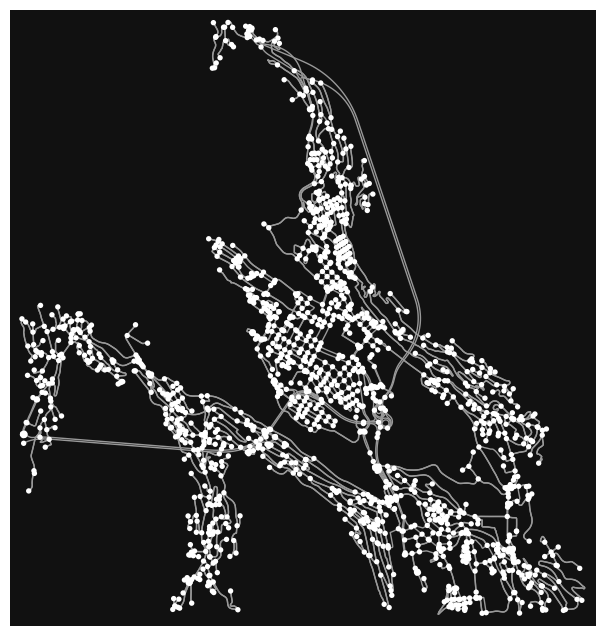

In [25]:
fig, ax = ox.plot_graph(G)

In [26]:
bbox = ox.utils_geo.bbox_from_point(
    center,
    dist=3000
)

bbox

(np.float64(5.269540737806679),
 np.float64(60.36601038993521),
 np.float64(5.378759262193322),
 np.float64(60.41996961006478))

In [27]:
url = "https://nobil.no/api/server/search.php"

west, south, east, north = ox.utils_geo.bbox_from_point(
    center,
    dist=3000
)

params = {
    "apikey": NOBIL_API_KEY,
    "apiversion": "3",
    "action": "search",
    "type": "rectangle",
    "northeast": f"({north}, {east})",
    "southwest": f"({south}, {west})",
    "limit": "100",
    "format": "json"
}

response = requests.get(url, params=params)
response.raise_for_status()

data = response.json()

In [28]:
type(data), len(data)

(dict, 4)

In [29]:
data.keys() if isinstance(data, dict) else None

dict_keys(['Provider', 'Rights', 'apiver', 'chargerstations'])

In [30]:
stations = data["chargerstations"]

len(stations)

70

In [31]:
raw_coords = []

for station in data["chargerstations"]:
    position = station["csmd"]["Position"]

    lat, lon = (
        position
        .strip("()")
        .split(",")
    )

    raw_coords.append(
        (float(lat), float(lon))
    )

raw_lats = [lat for lat, lon in raw_coords]
raw_lons = [lon for lat, lon in raw_coords]

print("API latitude:", min(raw_lats), max(raw_lats))
print("API longitude:", min(raw_lons), max(raw_lons))

print()
print("Requested bbox:")
print("latitude:", south, north)
print("longitude:", west, east)

API latitude: 60.346611 60.438778
API longitude: 5.2687014 5.375045

Requested bbox:
latitude: 60.36601038993521 60.41996961006478
longitude: 5.269540737806679 5.378759262193322


In [32]:
data

{'Provider': 'NOBIL.no',
 'Rights': 'Creative Commons Attribution 4.0 International License',
 'apiver': '3',
 'chargerstations': [{'csmd': {'id': 75204,
    'name': 'Taxi - Erleveien',
    'ocpidb_mapping_stasjon_id': 'NO#BKK#BAYXQW2SSV9XC',
    'Street': 'Erleveien',
    'House_number': '22',
    'Zipcode': '5097',
    'City': 'BERGEN',
    'Municipality_ID': '4601',
    'Municipality': 'BERGEN',
    'County_ID': '46',
    'County': 'Vestland',
    'Description_of_location': None,
    'Owned_by': 'Eviny',
    'Operator': 'Eviny',
    'Number_charging_points': 8,
    'Position': '(60.361268,5.368839)',
    'Image': 'no.image.svg',
    'User_comment': None,
    'Contact_info': None,
    'Created': '2025-12-23 04:00:09',
    'Updated': '2026-06-26 18:02:16',
    'Station_status': 1,
    'Land_code': 'NOR',
    'International_id': 'NOR_75204'},
   'attr': {'st': {'24': {'attrtypeid': '24',
      'attrname': 'Open 24h',
      'attrvalid': '1',
      'trans': 'Yes',
      'attrval': '1'},


In [33]:
data["chargerstations"][4]["csmd"]

{'id': 69220,
 'name': 'Kilen garasjeanlegg - Frydenbø Eiendom',
 'ocpidb_mapping_stasjon_id': 'NO#KPE#1025',
 'Street': 'Tverrveien',
 'House_number': '7',
 'Zipcode': '5160',
 'City': 'LAKSEVÅG',
 'Municipality_ID': '4601',
 'Municipality': 'BERGEN',
 'County_ID': '46',
 'County': 'Vestland',
 'Description_of_location': None,
 'Owned_by': 'Frydenbø Eiendomsdrift AS',
 'Operator': 'Kople AS',
 'Number_charging_points': 16,
 'Position': '(60.384108,5.311363)',
 'Image': 'no.image.svg',
 'User_comment': None,
 'Contact_info': None,
 'Created': '2025-10-06 10:28:37',
 'Updated': '2026-09-02 19:17:38',
 'Station_status': 1,
 'Land_code': 'NOR',
 'International_id': 'NOR_69220'}

In [34]:
stations = data["chargerstations"]

rows = []

for station in stations:
    csmd = station["csmd"]

    rows.append({
        "id": csmd["id"],
        "name": csmd["name"],
        "street": csmd["Street"],
        "house_number": csmd["House_number"],
        "city": csmd["City"],
        "municipality": csmd["Municipality"],
        "operator": csmd["Operator"],
        "number_charging_points": csmd["Number_charging_points"],
        "position": csmd["Position"],
        "station_status": csmd["Station_status"]
    })

df = pd.DataFrame(rows)

In [35]:
df.head()

,id,name,street,house_number,city,municipality,operator,number_charging_points,position,station_status
0,75204,Taxi - Erleveien,Erleveien,22,BERGEN,BERGEN,Eviny,8,"(60.361268,5.368839)",1
1,14334,Villaveien UiB,Villaveien,10,BERGEN,BERGEN,Fount,4,"(60.38594,5.3241)",1
2,41442,Media City Bergen,"Lars Hilles gate 30, 5008 Bergen, Norge",,BERGEN,BERGEN,Wattif,1,"(60.385467,5.332755)",1
3,78560,SolheimsGarasjen,"Solheimsgaten 29, 5054 Bergen, Norway",,BERGEN,BERGEN,Wattif,18,"(60.375306,5.337727)",1
4,69220,Kilen garasjeanlegg - Frydenbø Eiendom,Tverrveien,7,LAKSEVÅG,BERGEN,Kople AS,16,"(60.384108,5.311363)",1


In [36]:
df[["latitude", "longitude"]] = (
    df["position"]
    .str.strip("()")
    .str.split(",", expand=True)
    .astype(float)
)

df[["name", "latitude", "longitude"]].head()

,name,latitude,longitude
0,Taxi - Erleveien,60.361268,5.368839
1,Villaveien UiB,60.385940,5.324100
2,Media City Bergen,60.385467,5.332755
3,SolheimsGarasjen,60.375306,5.337727
4,Kilen garasjeanlegg - Frydenbø Eiendom,60.384108,5.311363


In [37]:
chargers = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(
        df["longitude"],
        df["latitude"]
    ),
    crs="EPSG:4326"
)

chargers.head()

,id,name,street,house_number,city,municipality,operator,number_charging_points,position,station_status,latitude,longitude,geometry
0,75204,Taxi - Erleveien,Erleveien,22,BERGEN,BERGEN,Eviny,8,"(60.361268,5.368839)",1,60.361268,5.368839,POINT (5.36884 60.36127)
1,14334,Villaveien UiB,Villaveien,10,BERGEN,BERGEN,Fount,4,"(60.38594,5.3241)",1,60.385940,5.324100,POINT (5.3241 60.38594)
2,41442,Media City Bergen,"Lars Hilles gate 30, 5008 Bergen, Norge",,BERGEN,BERGEN,Wattif,1,"(60.385467,5.332755)",1,60.385467,5.332755,POINT (5.33276 60.38547)
3,78560,SolheimsGarasjen,"Solheimsgaten 29, 5054 Bergen, Norway",,BERGEN,BERGEN,Wattif,18,"(60.375306,5.337727)",1,60.375306,5.337727,POINT (5.33773 60.37531)
4,69220,Kilen garasjeanlegg - Frydenbø Eiendom,Tverrveien,7,LAKSEVÅG,BERGEN,Kople AS,16,"(60.384108,5.311363)",1,60.384108,5.311363,POINT (5.31136 60.38411)


In [38]:
# Remove stations that are not active
chargers = chargers[
    chargers["station_status"] == 1
].copy()

len(chargers)

70

In [39]:
chargers_local = chargers[
    chargers.geometry.x.between(west, east)
    & chargers.geometry.y.between(south, north)
].copy()

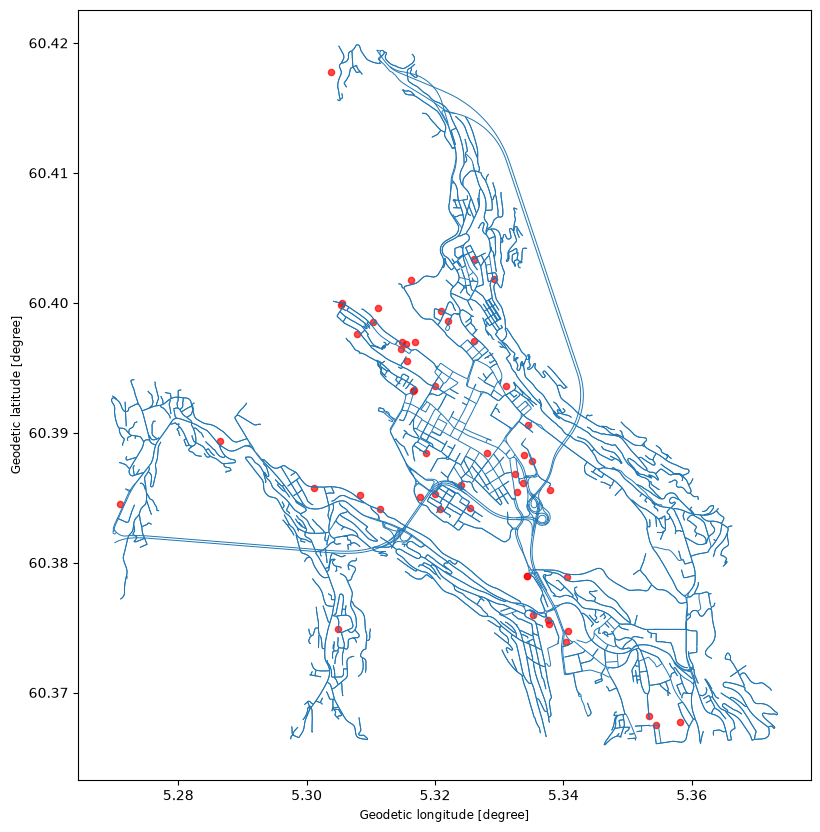

In [41]:
nodes, edges = ox.graph_to_gdfs(G)

fig, ax = plt.subplots(figsize=(10, 10))

edges.plot(
    ax=ax,
    linewidth=0.7
)

chargers_local.plot(
    ax=ax,
    markersize=20,
    color="red",
    alpha=0.7
)

plt.show()

In [42]:
print("Longitude:")
print(chargers_local.geometry.x.min(), chargers_local.geometry.x.max())

print("Latitude:")
print(chargers_local.geometry.y.min(), chargers_local.geometry.y.max())

Longitude:
5.2708776 5.358127
Latitude:
60.36752 60.41773


In [43]:
# Starting point
start_lat = 60.39299
start_lon = 5.32415

start_node = ox.distance.nearest_nodes(
    G,
    X=start_lon,
    Y=start_lat
)

start_node

3997336834

In [44]:
chargers_local["nearest_node"] = ox.distance.nearest_nodes(
    G,
    X=chargers_local.geometry.x,
    Y=chargers_local.geometry.y
)

chargers_local[
    ["name", "geometry", "nearest_node"]
].head()

,name,geometry,nearest_node
1,Villaveien UiB,POINT (5.3241 60.38594),29922468
2,Media City Bergen,POINT (5.33276 60.38547),29382276
3,SolheimsGarasjen,POINT (5.33773 60.37531),1682067113
4,Kilen garasjeanlegg - Frydenbø Eiendom,POINT (5.31136 60.38411),36486471
5,Solheimsgaten 5 - Eviny AS,POINT (5.33431 60.37894),769352808


In [ ]:
charger = chargers_local.iloc[0]

destination_node = charger["nearest_node"]

route = ox.routing.shortest_path(
    G,
    start_node,
    destination_node,
    weight="length"
)

route

[3997336834,
 25277303,
 3945886259,
 3945886257,
 674464,
 2025760535,
 674462,
 17345214,
 21397913,
 29869944,
 21634033,
 21634032,
 21397914,
 26117811,
 26117812,
 29382244,
 26462289,
 26462290,
 26462291,
 26462292,
 29922465,
 np.int64(29922468)]

In [46]:
route_edges = ox.routing.route_to_gdf(
    G,
    route,
    weight="length"
)

distance_m = route_edges["length"].sum()

distance_km = distance_m / 1000

distance_km

np.float64(1.3961376536422887)

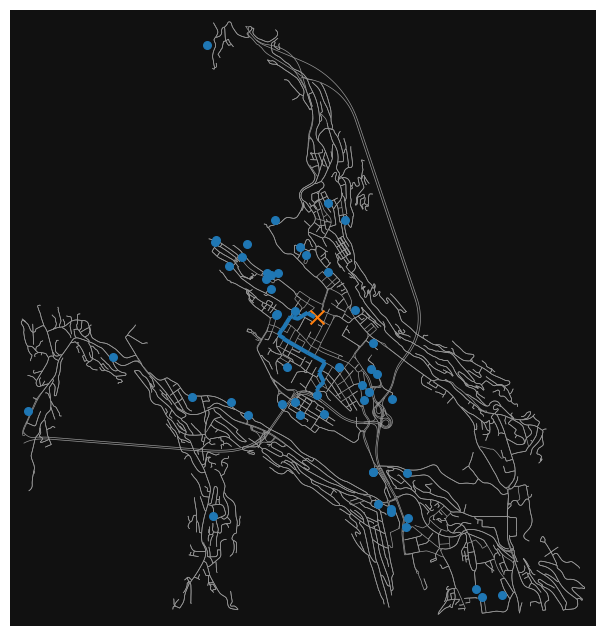

In [47]:
fig, ax = ox.plot_graph(
    G,
    show=False,
    close=False,
    node_size=0,
    edge_linewidth=0.5
)

route_edges.plot(
    ax=ax,
    linewidth=3
)

chargers_local.plot(
    ax=ax,
    markersize=30
)

start_gdf = gpd.GeoDataFrame(
    {"name": ["Start"]},
    geometry=[Point(start_lon, start_lat)],
    crs="EPSG:4326"
)

start_gdf.plot(
    ax=ax,
    marker="x",
    markersize=100
)

plt.show()

In [48]:
chargers_utm = chargers_local.to_crs(epsg=25832)
start_utm = start_gdf.to_crs(epsg=25832)

straight_line_m = chargers_utm.iloc[0].geometry.distance(
    start_utm.geometry.iloc[0]
)

print(f"Luftlinje: {straight_line_m / 1000:.2f} km")
print(f"Kjøreavstand: {distance_km:.2f} km")

Luftlinje: 0.79 km
Kjøreavstand: 1.40 km


In [49]:
charger_nodes, distances = ox.distance.nearest_nodes(
    G,
    X=chargers_local.geometry.x,
    Y=chargers_local.geometry.y,
    return_dist=True
)

chargers_local["nearest_node"] = charger_nodes
chargers_local["distance_to_node_m"] = distances

chargers_local[
    ["name", "nearest_node", "distance_to_node_m"]
].sort_values(
    "distance_to_node_m",
    ascending=False
).head(10)

,name,nearest_node,distance_to_node_m
18,Hegreneset,240061410,121.741727
60,St1 Lading Nygård,4336241780,120.886777
49,Tollbodallmenningen 5,674575,119.088745
9,Bontelabo AS - Bontelabo 2,645583,97.032777
37,Laksevåg kirke (offentlig),3401482485,91.218814
6,"Brann Stadion, Kniksens Plass 1",43523037,90.269448
65,Taxi - Bystasjonen,331534893,82.937562
39,Møhlenpris Hovedgård,25650620,82.733059
25,Sentraltind,36477098,82.578624
61,Plug - Holbergkaien Fjord1,29872374,81.083086


In [50]:
charger_nodes, distances = ox.distance.nearest_nodes(
    G,
    X=chargers_local.geometry.x,
    Y=chargers_local.geometry.y,
    return_dist=True
)
chargers_local[
    ["name", "distance_to_node_m"]
].sort_values(
    "distance_to_node_m",
    ascending=False
)
chargers_local["nearest_node"] = charger_nodes
chargers_local["distance_to_node_m"] = distances

In [60]:
chargers_local.head()

,id,name,street,house_number,city,municipality,operator,number_charging_points,position,station_status,latitude,longitude,geometry,nearest_node,distance_to_node_m,driving_distance_m
1,14334,Villaveien UiB,Villaveien,10,BERGEN,BERGEN,Fount,4,"(60.38594,5.3241)",1,60.385940,5.324100,POINT (5.3241 60.38594),29922468,39.622287,1396.137654
2,41442,Media City Bergen,"Lars Hilles gate 30, 5008 Bergen, Norge",,BERGEN,BERGEN,Wattif,1,"(60.385467,5.332755)",1,60.385467,5.332755,POINT (5.33276 60.38547),29382276,64.157195,1659.432842
3,78560,SolheimsGarasjen,"Solheimsgaten 29, 5054 Bergen, Norway",,BERGEN,BERGEN,Wattif,18,"(60.375306,5.337727)",1,60.375306,5.337727,POINT (5.33773 60.37531),1682067113,38.897186,2827.914487
4,69220,Kilen garasjeanlegg - Frydenbø Eiendom,Tverrveien,7,LAKSEVÅG,BERGEN,Kople AS,16,"(60.384108,5.311363)",1,60.384108,5.311363,POINT (5.31136 60.38411),36486471,57.228950,2241.908386
5,69255,Solheimsgaten 5 - Eviny AS,Solheimsgaten,5,BERGEN,BERGEN,Kople AS,27,"(60.378943,5.334308)",1,60.378943,5.334308,POINT (5.33431 60.37894),769352808,38.990513,2325.351570


In [52]:
def get_driving_distance(G, start_node, destination_node):
    route = ox.routing.shortest_path(
        G,
        start_node,
        destination_node,
        weight="length"
    )

    if route is None:
        return None

    route_edges = ox.routing.route_to_gdf(
        G,
        route,
        weight="length"
    )

    return route_edges["length"].sum()

In [53]:
get_driving_distance(
    G,
    start_node,
    destination_node
)

np.float64(1396.1376536422888)

In [54]:
driving_distances = []

for node in chargers_local["nearest_node"]:
    distance = get_driving_distance(
        G,
        start_node,
        node
    )

    driving_distances.append(distance)

chargers_local["driving_distance_m"] = driving_distances

In [57]:
chargers_local[
    ["name", "driving_distance_m"]
].sort_values("driving_distance_m")[:4]

,name,driving_distance_m
30,Citypark - 8575,192.689339
59,KlosterGarasjen,640.427579
32,Holbergsallmenningen (offentlig),677.322876
42,"Klostergarasjen, Bergen",684.310371


In [61]:
nearest_charger = chargers_local.loc[
    chargers_local["driving_distance_m"].idxmin()
]

nearest_charger

id                                             70704
name                                 Citypark - 8575
street                                    Markeveien
house_number                                       7
city                                          BERGEN
municipality                                  BERGEN
operator                                 Aimo Charge
number_charging_points                             6
position                        (60.393579,5.319994)
station_status                                     1
latitude                                   60.393579
longitude                                   5.319994
geometry                  POINT (5.319994 60.393579)
nearest_node                                  674469
distance_to_node_m                         48.356494
driving_distance_m                        192.689339
Name: 30, dtype: object

## Compare driving distance and straight-line distance to nearest node

In [73]:
chargers_utm = chargers_local.to_crs(25832)

start_gdf = gpd.GeoDataFrame(
    geometry=[Point(start_lon, start_lat)],
    crs="EPSG:4326"
)

start_utm = start_gdf.to_crs(25832)

chargers_utm["straight_line_m"] = chargers_utm.distance(
    start_utm.geometry.iloc[0]
)

nearest_straight = chargers_utm.loc[
    chargers_utm["straight_line_m"].idxmin()
]

print("Nearest by straight line:")
print(
    f"{nearest_straight['name']}\n"
    f"{nearest_straight['straight_line_m']:.2f} meters"
)

print()

print("Nearest by driving distance:")
print(
    f"{nearest_charger['name']}\n"
    f"{nearest_charger['driving_distance_m']:.2f} meters"
)

Nearest by straight line:
Citypark - 8575
238.38 meters

Nearest by driving distance:
Citypark - 8575
192.69 meters


In [72]:
comparison = chargers_local[
    ["name", "driving_distance_m"]
].copy()

comparison["straight_line_m"] = chargers_utm[
    "straight_line_m"
]

comparison.sort_values("driving_distance_m").head(10)

,name,driving_distance_m,straight_line_m
30,Citypark - 8575,192.689339,238.383576
59,KlosterGarasjen,640.427579,421.375757
32,Holbergsallmenningen (offentlig),677.322876,552.150738
42,"Klostergarasjen, Bergen",684.310371,408.611241
61,Plug - Holbergkaien Fjord1,820.394481,598.770693
28,C. Sundts gate 37 - JEM Invest AS,820.394481,642.864771
26,C. Sundts gate 39 - AS Mowinckelgården,964.610560,680.778688
20,Strandgaten 198 AS,1003.911130,645.947348
35,Sydnesplassen (offentlig),1015.563945,593.666588
51,Fagskulen Vestland. Nordnes Bergen - Vestland ...,1028.825746,1035.302061


In [74]:
invalid_distances = comparison[
    comparison["driving_distance_m"] < comparison["straight_line_m"]
]

invalid_distances

,name,driving_distance_m,straight_line_m
30,Citypark - 8575,192.689339,238.383576
51,Fagskulen Vestland. Nordnes Bergen - Vestland ...,1028.825746,1035.302061


### Compare a restricted search to the brute force method

The brute force method ensures that we get the optimal solution, but is computationally expensive as we end up calculating the distance to every single charging station in the data set. I want to limit the search area by assigning a search radius from the starting point and compare the result with the brute force method.

In [75]:
chargers_local["driving_distance_m"] = [
    get_driving_distance(
        G,
        start_node,
        node
    )
    for node in chargers_local["nearest_node"]
]

nearest_driving = chargers_local.loc[
    chargers_local["driving_distance_m"].idxmin()
]

chargers_utm = chargers_local.to_crs(25832)
start_utm = start_gdf.to_crs(25832)

chargers_utm["straight_line_m"] = chargers_utm.distance(
    start_utm.geometry.iloc[0]
)

nearest_straight = chargers_utm.loc[
    chargers_utm["straight_line_m"].idxmin()
]

print("Nearest by straight line:")
print(
    f"{nearest_straight['name']}\n"
    f"{nearest_straight['straight_line_m']:.2f} meters"
)

print()

print("Nearest by driving distance:")
print(
    f"{nearest_driving['name']}\n"
    f"{nearest_driving['driving_distance_m']:.2f} meters"
)

Nearest by straight line:
Citypark - 8575
238.38 meters

Nearest by driving distance:
Citypark - 8575
192.69 meters


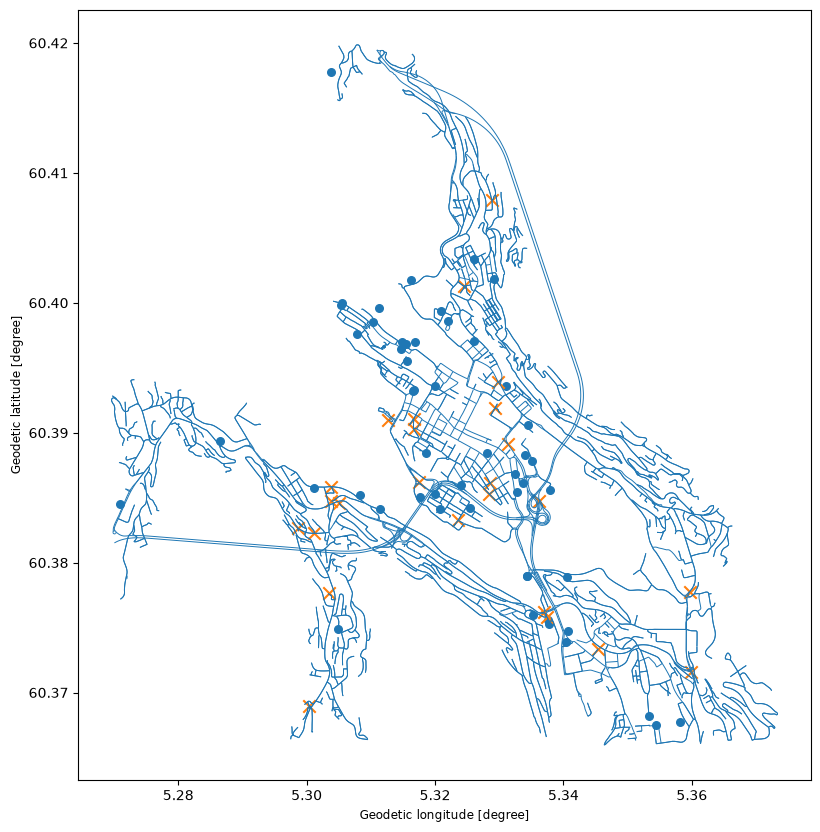

In [ ]:
RANDOM_SEED = 11

rng = np.random.default_rng(RANDOM_SEED)

all_nodes = np.array(list(G.nodes))

random_start_nodes = rng.choice(
    all_nodes,
    size=25,
    replace=False
)

random_start_points = []

for node in random_start_nodes:
    random_start_points.append({
        "node": node,
        "latitude": G.nodes[node]["y"],
        "longitude": G.nodes[node]["x"]
    })

start_points_df = pd.DataFrame(random_start_points)

start_points_df.head()

start_points_gdf = gpd.GeoDataFrame(
    start_points_df,
    geometry=gpd.points_from_xy(
        start_points_df["longitude"],
        start_points_df["latitude"]
    ),
    crs="EPSG:4326"
)

start_points_gdf = gpd.GeoDataFrame(
    start_points_df,
    geometry=gpd.points_from_xy(
        start_points_df["longitude"],
        start_points_df["latitude"]
    ),
    crs="EPSG:4326"
)

fig, ax = plt.subplots(figsize=(10, 10))

edges.plot(
    ax=ax,
    linewidth=0.7
)

chargers_local.plot(
    ax=ax,
    markersize=30
)

start_points_gdf.plot(
    ax=ax,
    marker="x",
    markersize=80
)

plt.show()

In [ ]:
def generate_random_start_points(G, n=25, seed=11):
    rng = np.random.default_rng(seed)

    all_nodes = np.array(list(G.nodes))

    random_nodes = rng.choice(
        all_nodes,
        size=n,
        replace=False
    )

    start_points_df = pd.DataFrame({
        "node": random_nodes,
        "latitude": [G.nodes[node]["y"] for node in random_nodes],
        "longitude": [G.nodes[node]["x"] for node in random_nodes]
    })

    start_points_gdf = gpd.GeoDataFrame(
        start_points_df,
        geometry=gpd.points_from_xy(
            start_points_df["longitude"],
            start_points_df["latitude"]
        ),
        crs="EPSG:4326"
    )

    return start_points_gdf



In [104]:
largest_scc = max(
    nx.strongly_connected_components(G),
    key=len
)

len(largest_scc)

1545

In [105]:
chargers_routable = chargers_local[
    chargers_local["nearest_node"].isin(largest_scc)
].copy()

print(len(chargers_local))
print(len(chargers_routable))

52
50


In [106]:
def generate_random_start_points(G, n=25, seed=11):
    rng = np.random.default_rng(seed)

    largest_scc = max(
        nx.strongly_connected_components(G),
        key=len
    )

    valid_nodes = np.array(list(largest_scc))

    random_nodes = rng.choice(
        valid_nodes,
        size=n,
        replace=False
    )

    start_points_df = pd.DataFrame({
        "node": random_nodes,
        "latitude": [G.nodes[node]["y"] for node in random_nodes],
        "longitude": [G.nodes[node]["x"] for node in random_nodes]
    })

    return gpd.GeoDataFrame(
        start_points_df,
        geometry=gpd.points_from_xy(
            start_points_df["longitude"],
            start_points_df["latitude"]
        ),
        crs="EPSG:4326"
    )

In [107]:
RANDOM_SEED = 11

start_points_gdf = generate_random_start_points(
    G,
    n=25,
    seed=RANDOM_SEED
)

start_points_gdf.head()

,node,latitude,longitude,geometry
0,3947963279,60.371962,5.360212,POINT (5.36021 60.37196)
1,13684842014,60.367942,5.305059,POINT (5.30506 60.36794)
2,9021354652,60.373910,5.341413,POINT (5.34141 60.37391)
3,83046206,60.410076,5.326769,POINT (5.32677 60.41008)
4,60480487,60.375052,5.344394,POINT (5.34439 60.37505)


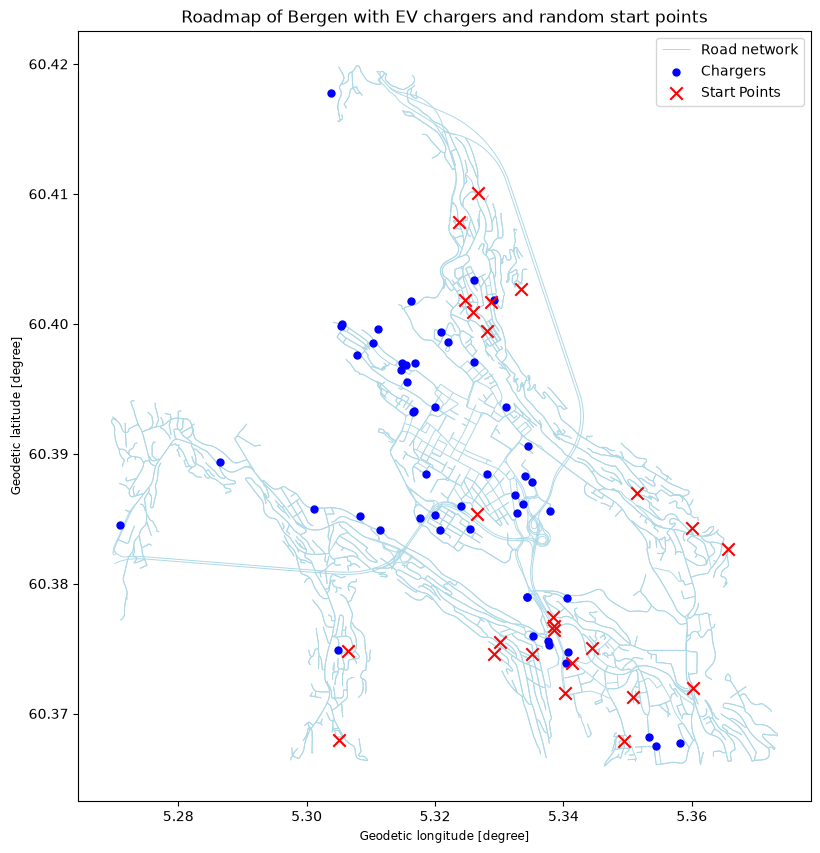

In [108]:
fig, ax = plt.subplots(figsize=(10, 10))

edges.plot(
    ax=ax,
    color="lightblue",
    linewidth=0.7,
    zorder=1,
    label="Road network"
)

chargers_local.plot(
    ax=ax,
    color="blue",
    markersize=25,
    zorder=2,
    label="Chargers"
)

start_points_gdf.plot(
    ax=ax,
    color="red",
    marker="x",
    markersize=80,
    zorder=3,
    label="Start Points"
)

ax.legend()
plt.title("Roadmap of Bergen with EV chargers and random start points")

plt.show()

In [109]:
def get_driving_distance(G, start_node, destination_node):
    try:
        return nx.shortest_path_length(
            G,
            source=start_node,
            target=destination_node,
            weight="length"
        )
    except nx.NetworkXNoPath:
        return np.nan

In [114]:
def find_nearest_bruteforce(G, chargers, start_node):
    distances = nx.single_source_dijkstra_path_length(
        G,
        source=start_node,
        weight="length"
    )

    charger_distances = chargers["nearest_node"].map(distances)

    valid_distances = charger_distances.dropna()

    if valid_distances.empty:
        return None

    nearest_idx = valid_distances.idxmin()

    return {
        "charger_idx": nearest_idx,
        "charger_name": chargers.loc[nearest_idx, "name"],
        "driving_distance_m": valid_distances.loc[nearest_idx],
        "n_candidates": len(valid_distances)
    }

In [115]:
def find_nearest_k_candidates(
    G,
    chargers_utm,
    start_point_utm,
    start_node,
    k
):
    straight_line_distances = chargers_utm.geometry.distance(
        start_point_utm
    )

    candidates = chargers_utm.copy()
    candidates["straight_line_m"] = straight_line_distances

    candidates = candidates.nsmallest(
        k,
        "straight_line_m"
    ).copy()

    candidates["driving_distance_m"] = (
        candidates["nearest_node"].apply(
            lambda node: get_driving_distance(
                G,
                start_node,
                node
            )
        )
    )

    candidates = candidates.dropna(
        subset=["driving_distance_m"]
    )

    nearest_idx = candidates["driving_distance_m"].idxmin()

    return {
        "charger_idx": nearest_idx,
        "charger_name": candidates.loc[nearest_idx, "name"],
        "driving_distance_m": candidates.loc[
            nearest_idx,
            "driving_distance_m"
        ],
        "straight_line_m": candidates.loc[
            nearest_idx,
            "straight_line_m"
        ],
        "n_candidates": len(candidates)
    }

In [121]:
def evaluate_start_points(
    G,
    chargers,
    start_points,
    k=5,
    projected_crs="EPSG:25832"
):
    chargers_utm = chargers.to_crs(projected_crs)
    start_points_utm = start_points.to_crs(projected_crs)

    results = []

    for idx, start in start_points.iterrows():

        start_node = start["node"]

        brute = find_nearest_bruteforce(
            G,
            chargers,
            start_node
        )

        candidate = find_nearest_k_candidates(
            G,
            chargers_utm,
            start_points_utm.loc[idx].geometry,
            start_node,
            k
        )

        results.append({
            "start_idx": idx,
            "start_node": start_node,

            "brute_idx": brute["charger_idx"],
            "brute_charger": brute["charger_name"],
            "brute_distance_m": brute["driving_distance_m"],

            "candidate_idx": candidate["charger_idx"],
            "candidate_charger": candidate["charger_name"],
            "candidate_distance_m": candidate["driving_distance_m"],

            "k": k,
            "correct": brute["charger_idx"] == candidate["charger_idx"]
        })

    return pd.DataFrame(results)

In [122]:
results_k5 = evaluate_start_points(
    G,
    chargers_local,
    start_points_gdf,
    k=5
)

results_k5.head()

,start_idx,start_node,brute_idx,brute_charger,brute_distance_m,candidate_idx,candidate_charger,candidate_distance_m,k,correct
0,0,3947963279,11,St. Olavs vei (offentlig),1211.570076,11,St. Olavs vei (offentlig),1211.570076,5,True
1,1,13684842014,45,Melkeplassen - Vestland fylkeskommune,1158.108965,45,Melkeplassen - Vestland fylkeskommune,1158.108965,5,True
2,2,9021354652,69,Danmarksplass,94.850440,69,Danmarksplass,94.850440,5,True
3,3,83046206,15,Martin Vahls Gate (offentlig),957.407728,15,Martin Vahls Gate (offentlig),957.407728,5,True
4,4,60480487,5,Solheimsgaten 5 - Eviny AS,878.709043,46,Solheimsgarasjen,1273.958995,5,False


In [123]:
k_values = [1, 3, 5, 10, 15, 20]

summary = []

for k in k_values:
    results = evaluate_start_points(
        G,
        chargers_routable,
        start_points_gdf,
        k=k
    )

    summary.append({
        "k": k,
        "correct": results["correct"].sum(),
        "total": len(results),
        "accuracy": results["correct"].mean()
    })

summary_df = pd.DataFrame(summary)

summary_df

,k,correct,total,accuracy
0,1,14,25,0.56
1,3,19,25,0.76
2,5,20,25,0.80
3,10,23,25,0.92
4,15,24,25,0.96
5,20,25,25,1.00


In [124]:
false_case = results_k5.loc[~results_k5["correct"]].iloc[0]

false_case

start_idx                                        4
start_node                                60480487
brute_idx                                        5
brute_charger           Solheimsgaten 5 - Eviny AS
brute_distance_m                        878.709043
candidate_idx                                   46
candidate_charger                 Solheimsgarasjen
candidate_distance_m                   1273.958995
k                                                5
correct                                      False
Name: 4, dtype: object

In [125]:
start_node = false_case["start_node"]
brute_idx = false_case["brute_idx"]
candidate_idx = false_case["candidate_idx"]

brute_node = chargers_routable.loc[brute_idx, "nearest_node"]
candidate_node = chargers_routable.loc[candidate_idx, "nearest_node"]

In [126]:
def get_route_and_edges(G, start_node, destination_node):
    route = nx.shortest_path(
        G,
        source=start_node,
        target=destination_node,
        weight="length"
    )

    if len(route) < 2:
        return route, None

    route_edges = ox.routing.route_to_gdf(
        G,
        route,
        weight="length"
    )

    return route, route_edges

In [127]:
brute_route, brute_edges = get_route_and_edges(
    G,
    start_node,
    brute_node
)

candidate_route, candidate_edges = get_route_and_edges(
    G,
    start_node,
    candidate_node
)

In [128]:
from shapely.geometry import Point
import geopandas as gpd

start_point_gdf = gpd.GeoDataFrame(
    {"label": ["Start point"]},
    geometry=[Point(G.nodes[start_node]["x"], G.nodes[start_node]["y"])],
    crs="EPSG:4326"
)

brute_charger_gdf = chargers_routable.loc[[brute_idx]].copy()
candidate_charger_gdf = chargers_routable.loc[[candidate_idx]].copy()

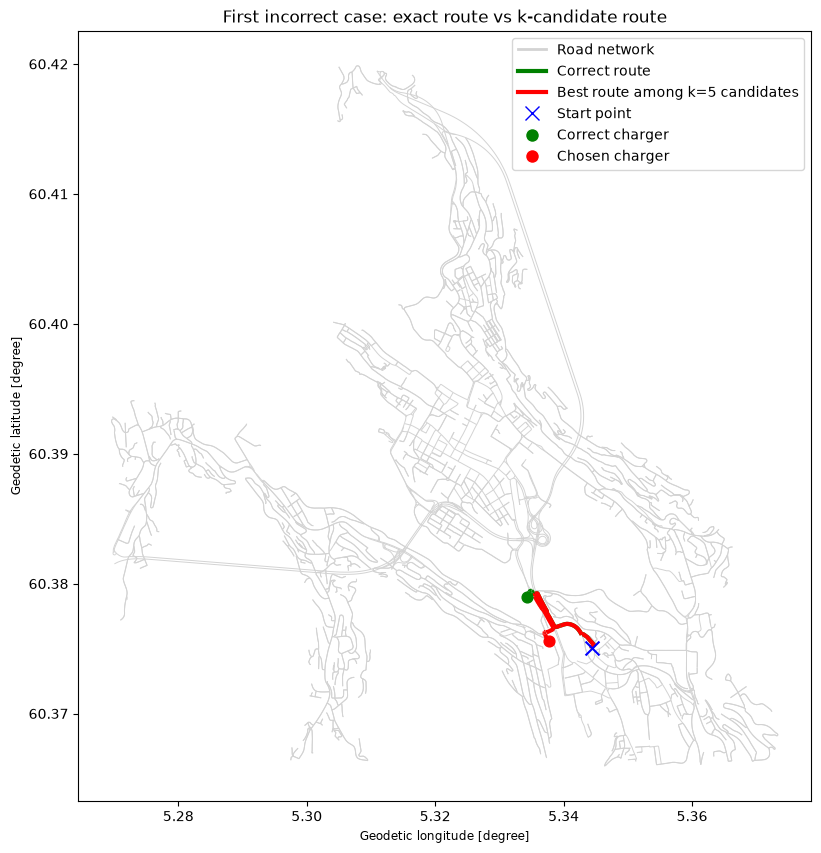

In [129]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(10, 10))

# Veinett
edges.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.7,
    zorder=1
)

# Korrekt rute
if brute_edges is not None:
    brute_edges.plot(
        ax=ax,
        color="green",
        linewidth=3,
        zorder=3
    )

# Kandidatrute
if candidate_edges is not None:
    candidate_edges.plot(
        ax=ax,
        color="red",
        linewidth=3,
        zorder=4
    )

# Startpunkt
start_point_gdf.plot(
    ax=ax,
    color="blue",
    marker="x",
    markersize=100,
    zorder=5
)

# Korrekt lader
brute_charger_gdf.plot(
    ax=ax,
    color="green",
    markersize=60,
    zorder=6
)

# Kandidatlader
candidate_charger_gdf.plot(
    ax=ax,
    color="red",
    markersize=60,
    zorder=7
)

# Legende
legend_elements = [
    Line2D([0], [0], color="lightgray", lw=2, label="Road network"),
    Line2D([0], [0], color="green", lw=3, label="Correct route"),
    Line2D([0], [0], color="red", lw=3, label=f"Best route among k={false_case['k']} candidates"),
    Line2D([0], [0], marker="x", color="blue", linestyle="None", markersize=10, label="Start point"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="green", markersize=10, label="Correct charger"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="red", markersize=10, label="Chosen charger")
]

ax.legend(handles=legend_elements, loc="best")

ax.set_title("First incorrect case: exact route vs k-candidate route")

plt.show()

In [130]:
false_case = results_k5.loc[
    ~results_k5["correct"]
].iloc[0]

start_idx = false_case["start_idx"]
k = int(false_case["k"])

chargers_utm = chargers_routable.to_crs(25832)
start_points_utm = start_points_gdf.to_crs(25832)

start_geometry = start_points_utm.loc[start_idx].geometry

straight_distances = chargers_utm.geometry.distance(
    start_geometry
)

candidate_indices = straight_distances.nsmallest(k).index

candidates = chargers_routable.loc[candidate_indices].copy()

candidates["straight_line_m"] = straight_distances.loc[
    candidate_indices
]

candidates = candidates.sort_values("straight_line_m")

candidates[
    ["name", "straight_line_m"]
]

,name,straight_line_m
40,Årstad VGS - Vestland fylkeskommune,204.675819
69,Danmarksplass,251.284319
3,SolheimsGarasjen,368.946458
46,Solheimsgarasjen,376.731209
25,Sentraltind,474.085105


In [131]:
candidates["candidate_rank"] = range(1, len(candidates) + 1)

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

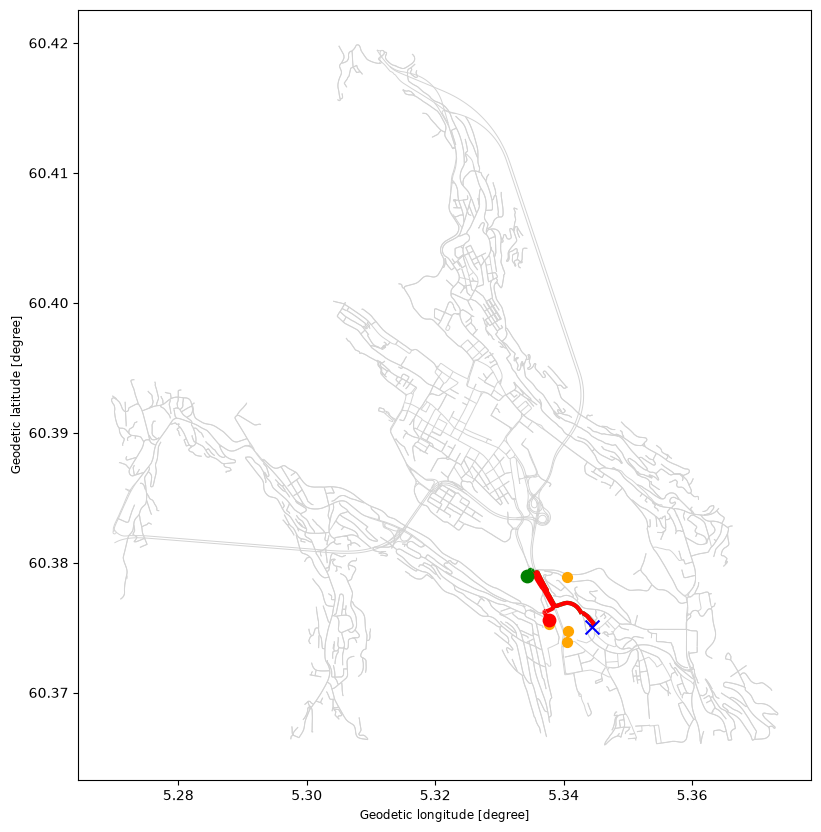

In [132]:
fig, ax = plt.subplots(figsize=(10, 10))

# Road network
edges.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.7,
    zorder=1
)

# All k candidates
candidates.plot(
    ax=ax,
    color="orange",
    markersize=50,
    zorder=3
)

# Correct route
brute_edges.plot(
    ax=ax,
    color="green",
    linewidth=3,
    zorder=4
)

# Route chosen by candidate method
candidate_edges.plot(
    ax=ax,
    color="red",
    linewidth=3,
    zorder=5
)

# Start point
start_point_gdf.plot(
    ax=ax,
    color="blue",
    marker="x",
    markersize=100,
    zorder=6
)

# Correct charger
brute_charger_gdf.plot(
    ax=ax,
    color="green",
    markersize=80,
    zorder=7
)

# Chosen charger
candidate_charger_gdf.plot(
    ax=ax,
    color="red",
    markersize=80,
    zorder=8
)